# Mejora acotada de la fase 3 — PRF Brasil

Ocho configuraciones, 24 ajustes CV y una nueva prueba cronológica. Se conserva el experimento anterior. Material de apoyo con IA que el grupo debe verificar y comprender.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
HERE=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'mejorar.py').exists())
sys.path.insert(0,str(HERE))
OUT=HERE/'output'
pd.set_option('display.max_columns',16)
display(json.loads((HERE/'protocolo.json').read_text(encoding='utf8')))

{'fecha': '2026-10-31',
 'objetivo': 'Ronda acotada de mejora de clasificacion herida/fallecida, conservando el experimento original',
 'semilla': 42,
 'presupuesto': '8 configuraciones LightGBM x 3 cortes = 24 ajustes CV; dos ajustes finales; sin ampliaciones segun resultados de prueba',
 'entrenamiento_final': '2017-2023, mismo periodo para referencia y candidato, aislando cambios de variables/ajustes',
 'CV': [{'train_hasta': 2020, 'validar': 2021},
  {'train_hasta': 2021, 'validar': 2022},
  {'train_hasta': 2022, 'validar': 2023}],
 'seleccion': 'Mayor AP media; el candidato debe superar referencia en media y en al menos 2 de 3 cortes. Si ninguno cumple se conserva referencia. ROC AUC y F1 se reportan, no eligen retrospectivamente.',
 'calibracion': '2024 enero-junio; sigmoid con prevalencia natural, igual para ambos modelos',
 'umbral': '2024 julio-diciembre; maximizar F1 de fallecidos, desempate por mayor umbral; regla secundaria recall>=0.80',
 'comparacion_2025': 'Retrospectiva

## Preparación y contexto vehicular

Se incluyen todos los vehículos identificados del accidente antes de seleccionar víctimas; se deduplican por claves reales y se resta el vehículo propio. Así se evita construir contexto únicamente con lesionados. Marca es un prefijo aproximado, y trazados compuestos se separan en indicadores. No se usan conteos de víctimas o gravedad como predictores.

In [2]:
from mejorar import main as ejecutar
ejecutar()
display(pd.read_csv(OUT/'auditoria_nuevas_variables_2017_2025.csv'))
display(json.loads((OUT/'diccionario_bloques.json').read_text(encoding='utf8')))

Ronda finalizada. Proyecto original intacto; ninguna decision cambiada despues de la prueba nueva.


,ano,victimas,accidentes,fallecidos,filas_fuente_personas,vehiculos_identificados_sin_duplicar,sin_union,duplicados_clave,filas_numero_vehiculos_informado,cantidad_max_vehiculos_declarados
0,2017,90567,58884,6248,224237,164625,0,0,90567,25.0
1,2018,81969,54079,5274,180061,129497,0,0,81969,21.0
2,2019,84535,55874,5340,176104,125797,0,0,84535,38.0
3,2020,76810,51982,5292,162245,118355,0,0,76810,25.0
4,2021,77270,52876,5397,166287,122056,0,0,77270,23.0
5,2022,78506,53100,5441,170825,122181,0,0,78506,28.0
6,2023,84090,56803,5627,183361,129748,0,0,84090,131.0
7,2024,90758,61420,6163,196448,139694,0,0,90758,26.0
8,2025,89593,61391,6043,194629,139517,0,0,89593,31.0


{'base': {'categoricas': ['sexo',
   'tipo_envolvido',
   'tipo_veiculo',
   'uf',
   'br',
   'municipio',
   'tipo_acidente',
   'fase_dia',
   'sentido_via',
   'condicao_metereologica',
   'tipo_pista',
   'tracado_via',
   'uso_solo',
   'dia_semana'],
  'numericas': ['idade',
   'idade_veiculo',
   'hora',
   'hora_sin',
   'hora_cos',
   'mes_sin',
   'mes_cos',
   'latitude',
   'longitude',
   'km'],
  'total': 24},
 'contexto': {'categoricas': ['sexo',
   'tipo_envolvido',
   'tipo_veiculo',
   'uf',
   'br',
   'municipio',
   'tipo_acidente',
   'fase_dia',
   'sentido_via',
   'condicao_metereologica',
   'tipo_pista',
   'tracado_via',
   'uso_solo',
   'dia_semana',
   'familia_otro_vehiculo'],
  'numericas': ['idade',
   'idade_veiculo',
   'hora',
   'hora_sin',
   'hora_cos',
   'mes_sin',
   'mes_cos',
   'latitude',
   'longitude',
   'km',
   'n_vehiculos_declarados',
   'n_vehiculos_identificados',
   'n_otros_vehiculos',
   'otros_pesados',
   'otras_motos',
   '

Los datos originales, modelos y métricas del primer experimento se verifican por hash y no se modifican. Si las salidas existen, se reutilizan los resultados registrados; desde cero se ejecuta la búsqueda y se congela la selección antes de abrir 2026. Reproducir resultados ya vistos no constituye una nueva prueba independiente.

## Búsqueda temporal acotada

Mismos cortes de 2021, 2022 y 2023. La regla elige mayor AP media con mejora en al menos dos cortes respecto de la referencia. La grilla no se amplía según la prueba.

,modelo,bloque,train_hasta,validar,n_train,n_validacion,AP,ROC_AUC,segundos
0,Referencia_24_original,base,2020,2021,333881,77270,0.282138,0.779022,5.241929
1,Referencia_24_original,base,2021,2022,411151,78506,0.279474,0.795708,5.937294
2,Referencia_24_original,base,2022,2023,489657,84090,0.285993,0.796804,7.113795
3,Contexto_mismo_ajuste,contexto,2020,2021,333881,77270,0.333488,0.819541,6.535795
4,Contexto_mismo_ajuste,contexto,2021,2022,411151,78506,0.329017,0.830501,6.273567
5,Contexto_mismo_ajuste,contexto,2022,2023,489657,84090,0.338741,0.838284,7.228363
6,Enriquecido_mismo_ajuste,enriquecido,2020,2021,333881,77270,0.335507,0.819652,5.594016
7,Enriquecido_mismo_ajuste,enriquecido,2021,2022,411151,78506,0.330611,0.830791,6.836171
8,Enriquecido_mismo_ajuste,enriquecido,2022,2023,489657,84090,0.341128,0.838468,7.846467
9,Contexto_regularizado,contexto,2020,2021,333881,77270,0.331637,0.819122,6.645049


,modelo,bloque,AP_media,AP_sd,AUC_media,cortes_supera_referencia,ganancia_AP_media,elegible
0,Contexto_regularizado_natural,contexto,0.338874,0.005573,0.831618,3,0.056339,True
1,Enriquecido_regularizado,enriquecido,0.337457,0.006027,0.830637,3,0.054922,True
2,Enriquecido_mismo_ajuste,enriquecido,0.335749,0.005263,0.829637,3,0.053214,True
3,Enriquecido_7_hojas,enriquecido,0.335503,0.005761,0.830341,3,0.052969,True
4,Enriquecido_31_hojas,enriquecido,0.334509,0.005787,0.828135,3,0.051975,True
5,Contexto_regularizado,contexto,0.334167,0.006001,0.829570,3,0.051632,True
6,Contexto_mismo_ajuste,contexto,0.333749,0.004867,0.829442,3,0.051214,True
7,Referencia_24_original,base,0.282535,0.003277,0.790511,0,0.000000,False


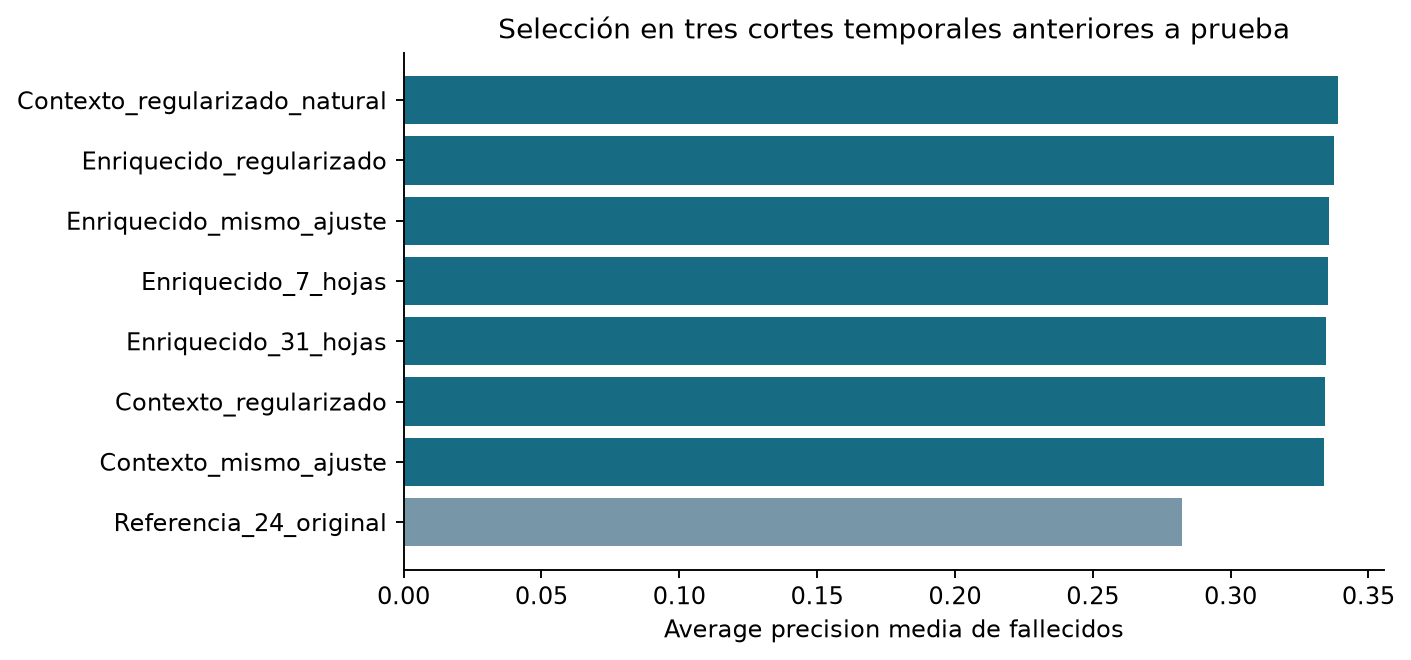

In [3]:
display(pd.read_csv(OUT/'validacion_temporal.csv'))
display(pd.read_csv(OUT/'ranking_CV.csv'))
display(Image(filename=str(OUT/'figures/01_busqueda_CV.png')))

## Congelamiento y evaluación

Ambos modelos usan desarrollo 2017–2023, calibración 2024 H1 y umbral 2024 H2. 2025 es comparación retrospectiva. 2026 se leyó después de congelar modelos/umbrales; se informa el período publicado, no el año completo.

In [4]:
display(json.loads((OUT/'congelamiento.json').read_text(encoding='utf8')))
display(json.loads((OUT/'auditoria_2026.json').read_text(encoding='utf8')))
metricas=pd.read_csv(OUT/'metricas_evaluacion.csv')
display(metricas[metricas.regla.eq('F1_validacion')])
display(pd.read_csv(OUT/'comparacion_completa.csv'))

{'protocolo_sha256': '5c55d2e715ffaa5746c1d5e0f1efc4095e1e6aa84a27872bff9ae90ca8351be0',
 'seleccionado': 'Contexto_regularizado_natural',
 'seleccion_solo_CV': True,
 'modelos': [{'nombre': 'Referencia_24_original',
   'spec': {'nombre': 'Referencia_24_original',
    'bloque': 'base',
    'hojas': 15,
    'arboles': 240,
    'tasa': 0.06,
    'min_hoja': 120,
    'l2': 8,
    'peso': 'raiz'},
   'features': ['sexo',
    'tipo_envolvido',
    'tipo_veiculo',
    'uf',
    'br',
    'municipio',
    'tipo_acidente',
    'fase_dia',
    'sentido_via',
    'condicao_metereologica',
    'tipo_pista',
    'tracado_via',
    'uso_solo',
    'dia_semana',
    'idade',
    'idade_veiculo',
    'hora',
    'hora_sin',
    'hora_cos',
    'mes_sin',
    'mes_cos',
    'latitude',
    'longitude',
    'km'],
   'umbral': 0.18655895245504792,
   'umbrales': {'F1_fallecido': 0.18655895245504792,
    'recall80': 0.04152721383789667},
   'archivo': 'models\\Referencia_24_original.joblib',
   'sha256'

{'ano': 2026,
 'victimas': 67591,
 'accidentes': 46337,
 'fallecidos': 4610,
 'filas_fuente_personas': 148868,
 'vehiculos_identificados_sin_duplicar': 106147,
 'sin_union': 0,
 'duplicados_clave': 0,
 'filas_numero_vehiculos_informado': 67591,
 'cantidad_max_vehiculos_declarados': 19.0,
 'fecha_min_archivo': '2026-01-01',
 'fecha_max_archivo': '2026-09-30',
 'fecha_min_victimas': '2026-01-01',
 'fecha_max_victimas': '2026-09-30',
 'dias_con_accidentes': 273,
 'filas_ocurrencias': 54895,
 'filas_personas': 148868,
 'estados_fisicos': {'Ileso': 59402,
  'Lesões Leves': 47985,
  'Lesões Graves': 14996,
  'NA': 13082,
  'Não Informado': 8793,
  'Óbito': 4610},
 'fecha_lectura_nueva_prueba_UTC': '2026-10-31T18:09:07.126890+00:00',
 'nota': 'Periodo publicado; no se presume anio completo ni seguimiento hospitalario a 30 dias'}

,modelo,particion,regla,n,fallecidos,prevalencia,umbral,AP,...,balanced_accuracy,accuracy,Brier,log_loss,TN,FP,FN,TP
0,Referencia_24_original,2025_retroactivo_ya_conocido,F1_validacion,89593,6043,0.067449,0.186559,0.302314,...,0.671377,0.901164,0.054366,0.201626,78286,5264,3591,2452
3,Referencia_24_original,2026_prueba_nueva,F1_validacion,67591,4610,0.068204,0.186559,0.297098,...,0.665797,0.899646,0.055231,0.205224,58987,3994,2789,1821
6,Contexto_regularizado_natural,2025_retroactivo_ya_conocido,F1_validacion,89593,6043,0.067449,0.214245,0.361358,...,0.689802,0.914770,0.051657,0.187664,79360,4190,3446,2597
9,Contexto_regularizado_natural,2026_prueba_nueva,F1_validacion,67591,4610,0.068204,0.214245,0.352292,...,0.685806,0.912207,0.052598,0.190564,59704,3277,2657,1953


,modelo,particion,regla,n,fallecidos,prevalencia,umbral,AP,...,balanced_accuracy,accuracy,Brier,log_loss,TN,FP,FN,TP
0,Referencia_24_original,entrenamiento_2017_2023,F1_validacion,573747,38619,0.067310,0.186559,0.394759,...,0.710236,0.913044,0.050463,0.182511,505478,29650,20241,18378
1,Referencia_24_original,validacion_umbral_2024_H2,F1_validacion,47236,3252,0.068846,0.186559,0.298293,...,0.670461,0.900182,0.055757,0.207212,41207,2777,1938,1314
2,Contexto_regularizado_natural,entrenamiento_2017_2023,F1_validacion,573747,38619,0.067310,0.214245,0.456459,...,0.723126,0.923935,0.047380,0.170762,511140,23988,19654,18965
3,Contexto_regularizado_natural,validacion_umbral_2024_H2,F1_validacion,47236,3252,0.068846,0.214245,0.357528,...,0.687379,0.913392,0.052972,0.191890,41762,2222,1869,1383
4,Referencia_24_original,2025_retroactivo_ya_conocido,F1_validacion,89593,6043,0.067449,0.186559,0.302314,...,0.671377,0.901164,0.054366,0.201626,78286,5264,3591,2452
5,Referencia_24_original,2025_retroactivo_ya_conocido,umbral_05,89593,6043,0.067449,0.500000,0.302314,...,0.535052,0.933935,0.054366,0.201626,83227,323,5596,447
6,Referencia_24_original,2025_retroactivo_ya_conocido,recall80_validacion,89593,6043,0.067449,0.041527,0.302314,...,0.720063,0.633788,0.054366,0.201626,51829,31721,1089,4954
7,Referencia_24_original,2026_prueba_nueva,F1_validacion,67591,4610,0.068204,0.186559,0.297098,...,0.665797,0.899646,0.055231,0.205224,58987,3994,2789,1821
8,Referencia_24_original,2026_prueba_nueva,umbral_05,67591,4610,0.068204,0.500000,0.297098,...,0.535363,0.933630,0.055231,0.205224,62763,218,4268,342
9,Referencia_24_original,2026_prueba_nueva,recall80_validacion,67591,4610,0.068204,0.041527,0.297098,...,0.713327,0.623678,0.055231,0.205224,38388,24593,843,3767


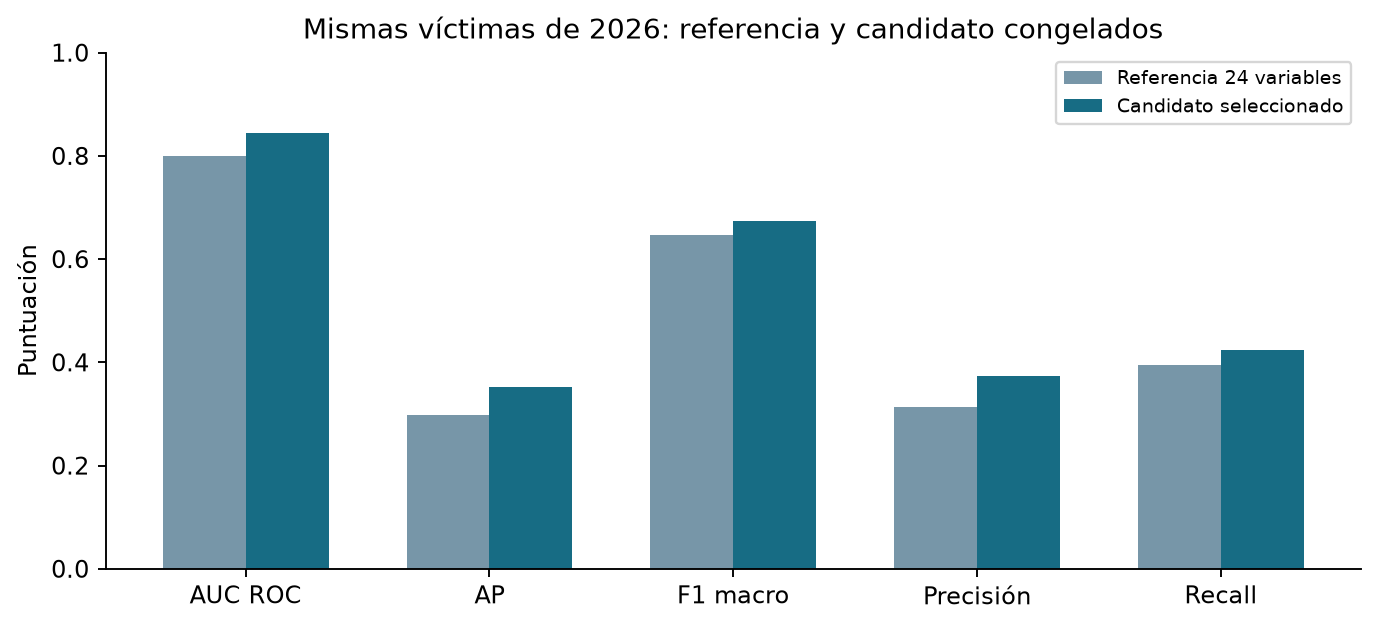

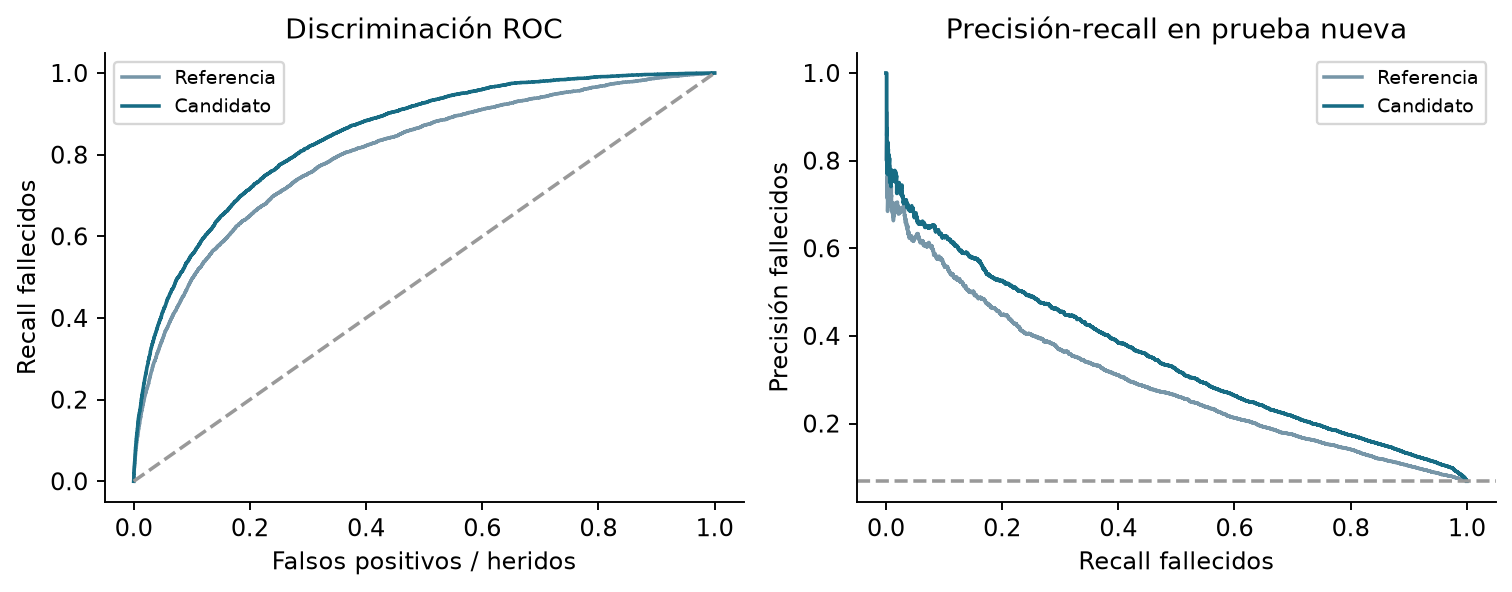

In [5]:
display(Image(filename=str(OUT/'figures/02_comparacion_2026.png')))
display(Image(filename=str(OUT/'figures/03_curvas_2026.png')))

AUC y AP miden ordenamiento; AP depende de la prevalencia y no es exactitud. La comparación se hace sobre idénticas víctimas. Precisión y recall dependen del umbral fijado con 2024. Una ganancia en AUC no implica ausencia de falsas alarmas o detección perfecta.

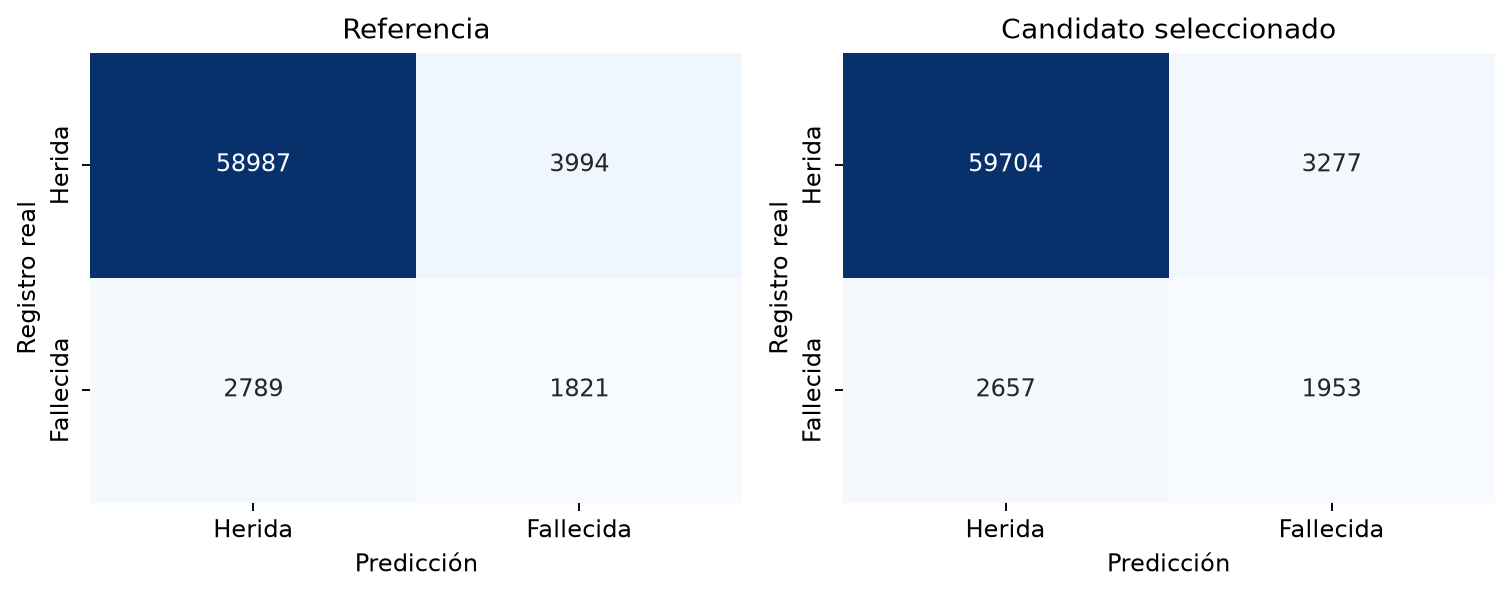

,modelo,particion,regla,n,fallecidos,prevalencia,umbral,AP,...,balanced_accuracy,accuracy,Brier,log_loss,TN,FP,FN,TP
3,Referencia_24_original,2026_prueba_nueva,F1_validacion,67591,4610,0.068204,0.186559,0.297098,...,0.665797,0.899646,0.055231,0.205224,58987,3994,2789,1821
4,Referencia_24_original,2026_prueba_nueva,umbral_05,67591,4610,0.068204,0.500000,0.297098,...,0.535363,0.933630,0.055231,0.205224,62763,218,4268,342
5,Referencia_24_original,2026_prueba_nueva,recall80_validacion,67591,4610,0.068204,0.041527,0.297098,...,0.713327,0.623678,0.055231,0.205224,38388,24593,843,3767
9,Contexto_regularizado_natural,2026_prueba_nueva,F1_validacion,67591,4610,0.068204,0.214245,0.352292,...,0.685806,0.912207,0.052598,0.190564,59704,3277,2657,1953
10,Contexto_regularizado_natural,2026_prueba_nueva,umbral_05,67591,4610,0.068204,0.500000,0.352292,...,0.568323,0.934547,0.052598,0.190564,62502,479,3945,665
11,Contexto_regularizado_natural,2026_prueba_nueva,recall80_validacion,67591,4610,0.068204,0.051130,0.352292,...,0.760475,0.718099,0.052598,0.190564,44805,18176,878,3732


,metrica,IC95_bajo,IC95_alto
0,delta_AP,0.047294,0.062425
1,delta_ROC_AUC,0.041235,0.049923
2,delta_F1_macro,0.021603,0.032713
3,delta_precision,0.050074,0.069804
4,delta_recall,0.016494,0.041310


In [6]:
display(Image(filename=str(OUT/'figures/04_confusion_2026.png')))
display(metricas[(metricas.particion.eq('2026_prueba_nueva'))])
display(pd.read_csv(OUT/'intervalos_mejora_2026.csv'))

## Incertidumbre y límites

Los intervalos usan 300 remuestras pareadas de accidentes completos. No corrigen todos los sesgos ni garantizan estabilidad posterior. Las características se observan en un siniestro ya ocurrido; la tarea no es anticipar quién se accidentará ni tomar decisiones clínicas. La nueva utilidad predictiva no prueba causalidad. Las hipótesis originales de fase 2 se conservan y las nuevas decisiones de preparación se documentan para integrar el proyecto.

In [7]:
display(json.loads((OUT/'verificacion.json').read_text(encoding='utf8')))

{'estado': 'OK',
 'archivos_originales_sin_cambios': {'models/modelo_seleccionado.joblib': 'dbdfed77b0b97050746b18a9c199476639ef4b54880e3519e7400164ecdde74d',
  'protocolo.json': '6dfef1669336164dd4120e20c842454189456d94d3d87fafce3050e2844adfed',
  'output/fase3_resultados.json': 'bbad450d2842588447ed7d925a1a6a44a1e9140a50df673602c21aac99d46ba8',
  'output/tables/metricas_prueba_2025.csv': '23ba4937d8bb6bae0b6a2923029efe36dfcada0f7cb93f4fce1e4e570c281ea2'},
 'seleccion': 'Contexto_regularizado_natural',
 'presupuesto_respetado': True}